In [1]:
# ═══════════════════════════════════════════════════════════════
# CELL 1 — Imports
# ═══════════════════════════════════════════════════════════════
from the_well.data.normalization import ZScoreNormalization
import sys, os, datetime, fsspec, torch, munch, toml, yaml
from the_well.data import WellDataModule
from torch.utils.data import DataLoader
import torch.nn.functional as F
import pytorch_lightning as pl
import shutil

PROJECT_ROOT = "/Users/gabrieleaccarino/Workspace/waveletflux"
sys.path.insert(0, PROJECT_ROOT)

from waveletflux.utils.configs import WaveletConfig, VelocityNetConfig, FlowMatchingConfig, OptimizerConfig
from waveletflux.utils.well_data import WellDataModuleLightning
from waveletflux.utils.augmentations import compose_augmentation
from waveletflux.utils.experiment import ExperimentManager
from waveletflux.modules.wavelet_fm import WaveletFlowModule
from waveletflux.models.wavelet_unet import WaveletFlowUNet

print("Imports OK | MPS:", torch.backends.mps.is_available())
print(f"MPS allocated : {torch.mps.current_allocated_memory() / 1e9:.2f} GB")
print(f"MPS reserved  : {torch.mps.driver_allocated_memory()  / 1e9:.2f} GB")

Imports OK | MPS: True
MPS allocated : 0.00 GB
MPS reserved  : 0.00 GB


In [2]:
well_base_path    = f"/Users/gabrieleaccarino/Workspace/multi-scale-wavelet-flow-matching/data/datasets"
well_dataset_name = 'rayleigh_benard'
stats_path        = f"{well_base_path}/{well_dataset_name}/stats.yaml"

In [3]:
augmentations = ['log_scalars']

base_data_module = WellDataModule(
    well_base_path     = well_base_path,
    well_dataset_name  = well_dataset_name,
    n_steps_input      = 4,
    n_steps_output     = 1,
    max_rollout_steps  = 1,
    batch_size         = 1,
    use_normalization  = False,
    normalization_type = None,
    transform          = compose_augmentation(*augmentations),
    data_workers       = 10,
    world_size         = 1,
    rank               = 0,
)


In [4]:
with fsspec.open(stats_path, mode='r') as f:
    stats = yaml.safe_load(f)

normalizer = ZScoreNormalization(
    stats,
    core_field_names          = base_data_module.train_dataset.core_field_names,
    core_constant_field_names = base_data_module.train_dataset.core_constant_field_names,
)

data_shape  = base_data_module.train_dataset.metadata.spatial_resolution
meta_fields = base_data_module.train_dataset.metadata.field_names
field_names = [item for sublist in meta_fields.values() for item in sublist]

print(f"Fields: {field_names} | Shape: {data_shape}")

Fields: ['buoyancy', 'pressure', 'velocity_x', 'velocity_y'] | Shape: (512, 128)


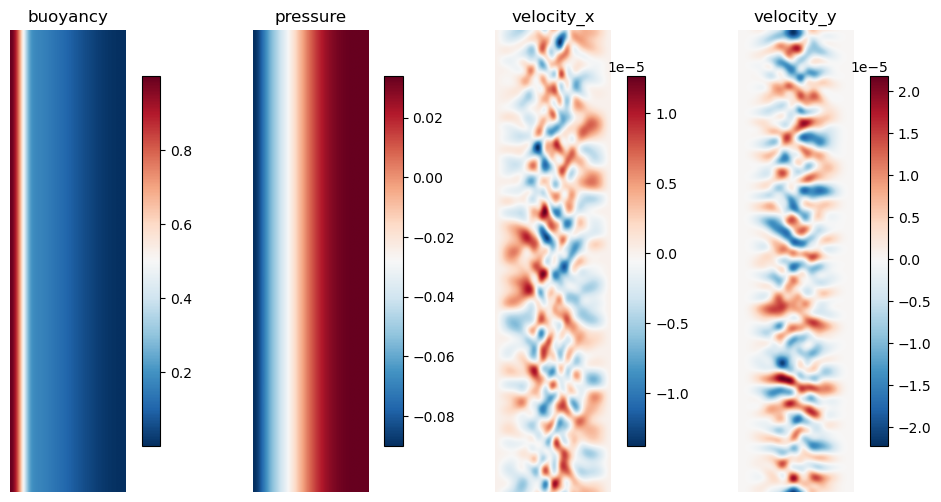

In [5]:
from matplotlib import pyplot as plt

item = base_data_module.train_dataset[0]
x = item['output_fields'] # (B, H, W, C)

plt.figure(figsize=(12, 6))

cmap = 'RdBu_r'

plt.subplot(1, 4, 1)
plt.title("buoyancy")
plt.imshow(x[0, ..., 0].numpy(), cmap=cmap)
plt.colorbar(shrink = 0.8, pad = 0.08)
plt.axis('off')

plt.subplot(1, 4, 2)
plt.title("pressure")
plt.imshow(x[0, ..., 1].numpy(), cmap=cmap)
plt.colorbar(shrink = 0.8, pad = 0.08)
plt.axis('off')

plt.subplot(1, 4, 3)
plt.title("velocity_x")
plt.imshow(x[0, ..., 2].numpy(), cmap=cmap)
plt.colorbar(shrink = 0.8, pad = 0.08)
plt.axis('off')

plt.subplot(1, 4, 4)
plt.title("velocity_y")
plt.imshow(x[0, ..., 3].numpy(), cmap=cmap)
plt.colorbar(shrink = 0.8, pad = 0.08)
plt.axis('off')

plt.show()